<div style="text-align: center;">
    <a href="https://www.hi-paris.fr/">
        <img border="0" src="https://www.hi-paris.fr/wp-content/uploads/2020/09/logo-hi-paris-retina.png" width="25%"></a>
    <a href="https://www.dataia.eu/">
        <img border="0" src="https://github.com/ramp-kits/template-kit/raw/main/img/DATAIA-h.png" width="70%"></a>
</div>

# Template Kit for Cadabench challenge in the Datacamp

<i> Thomas Moreau (Inria) </i><br/>
<i> Pedro Rodrigues (Inria) </i>

## Introduction

The data comes from a subset dataset (originally from MoleculeNet). (exactly ```molvision/BACE-V-SMILES-0``` but won't be precised to the participant to avoid data leakage). It contains SMILES representation for a set of molecules tested as inhibitors of the enzyme Beta-secretase 1.

**What is the task this challenge aims to solve?**

Your goal is to build a binary classification model that takes a molecule's SMILES string as input and predicts whether it is an active inhibitor (Label = 1) or an inactive molecule (Label = 0).

**Why does it matter?**

This enzyme is a prime therapeutic target for Alzheimer's disease. Being able to predict its inhibitors accurately accelerates the drug discovery process.

## Out-of-distribution test set 

This is not a standard random-split challenge. The dataset has been strictly split based on Molecular Weight (MW):

- Train set: it contains smaller molecules (MW < 592 Da).

- Hidden test set: it contains exclusively larger molecules (MW ≥ 592 Da).

Your model must prove it has learned true chemical rules to extrapolate to uncharted chemical space, rather than just memorizing the training statistics!

# Exploratory data analysis

In [29]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
# Load the data
from ingestion_program.ingestion import get_train_data
X, y = get_train_data("input_data")

In [30]:
print(f"Number of molecules in train set: {len(X)}")
X.head()

Number of molecules in train set: 683


0            Oc1ccc(cc1)CC[NH3+]
1              n1ccc2c(cccc2)c1N
2         Oc1ccc(cc1)CC([NH3+])C
3           O=C1NC(=NC(=C1)CCC)N
4    Oc1ccc(cc1C1CCCCC1)CC[NH3+]
Name: SMILES, dtype: object

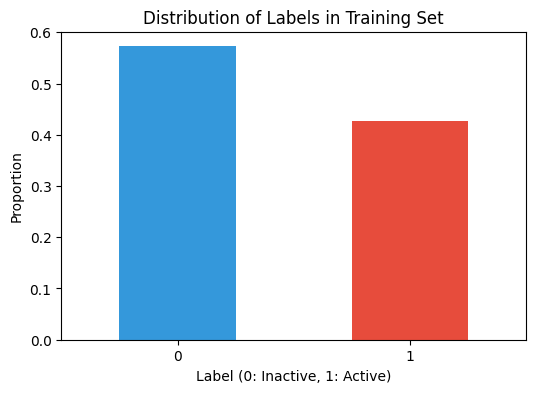

Label
0    391
1    292
Name: count, dtype: int64


In [31]:
plt.figure(figsize=(6, 4))
y.value_counts(normalize=True).plot(kind='bar', color=['#3498db', '#e74c3c'])
plt.title('Distribution of Labels in Training Set')
plt.xlabel('Label (0: Inactive, 1: Active)')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

print(y.value_counts())

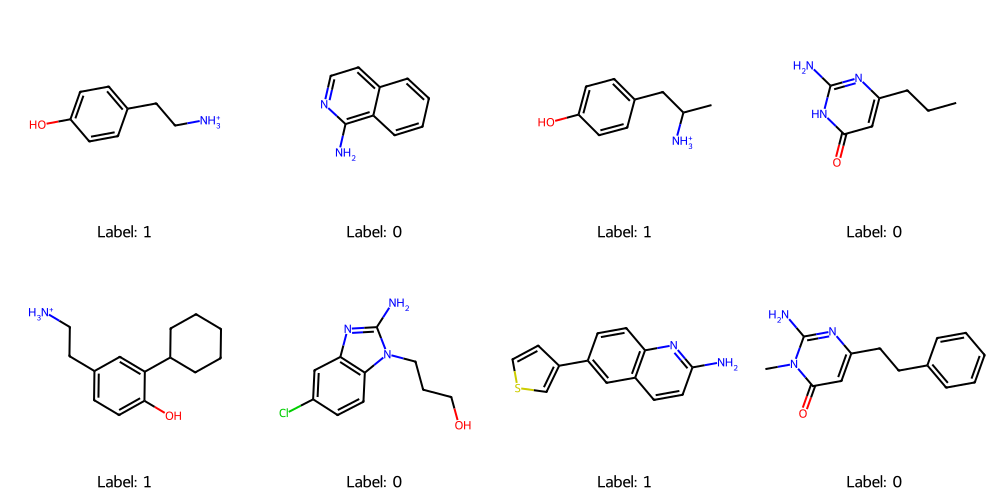

In [32]:
mols = [Chem.MolFromSmiles(smiles) for smiles in X.head(8)]
labels = [f"Label: {l}" for l in y.head(8).values]

# Plot them in a grid
img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(250, 250), legends=labels)
img

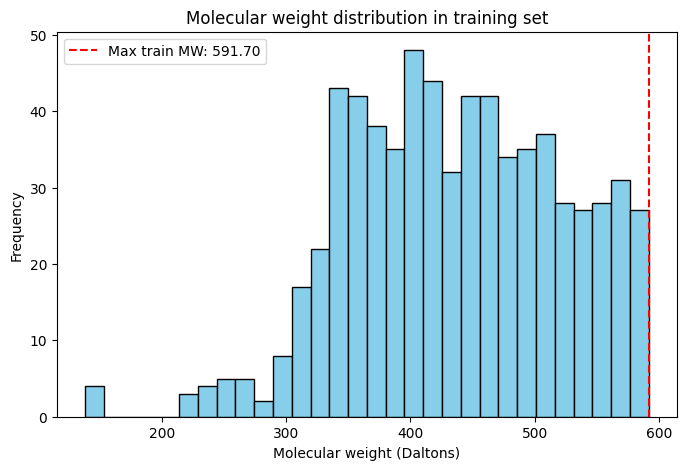

In [33]:
# Calculate Molecular Weight for all training molecules
MW = X.apply(lambda x: Descriptors.MolWt(Chem.MolFromSmiles(x)))

plt.figure(figsize=(8, 5))
plt.hist(MW, bins=30, color='skyblue', edgecolor='black')
plt.title('Molecular weight distribution in training set')
plt.xlabel('Molecular weight (Daltons)')
plt.ylabel('Frequency')
plt.axvline(x=MW.max(), color='red', linestyle='--', label=f'Max train MW: {MW.max():.2f}')
plt.legend()
plt.show()

The training set abruptly stops before 600 Daltons. Prepare your model to face much heavier molecules in the private test set.

# Challenge evaluation

A particularly important point in a challenge is to describe how it is evaluated. Because of the distribution shift (OOD) and the class imbalance, simple Accuracy is a terrible metric.

The metric used to evaluate your submission is the ```Cohen's Kappa Score```.
It evaluates the agreement between your predictions and reality while mathematically removing the probability of agreement occurring by pure chance.

# Submission format

Here, you should describe the submission format. This is the format the participants should follow to submit their predictions on the codabench platform.

In [34]:
# %load solution/submission.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin


class DeepLearningWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model_name="DeepLearningModel", epochs=3, batch_size=32):
        """
        # Init parameter model
        """
        self.model_name = model_name
        self.epochs = epochs
        self.batch_size = batch_size
        self.model = None # if torch or HF model
        self.tokenizer = None # tokenizer if needed
        
    def fit(self, X, y):
        """
        Training of the model
        X : List or pandas of SMILES
        y : Labels (0-1)
        """
        
        
        print(f"Model {self.model_name} trained.")
        
        # Should return 'self' to fit with scikit-learn API
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        """
        Proba prediction
        """
        np.random.seed(42)
        random_probs = np.random.rand(len(X))
        
        # Scikit-learn want a tabular of (n_samples, 2) for binary classification
        return np.vstack([1 - random_probs, random_probs]).T

    def predict(self, X):
        """
        Class prediction
        """
        # Utilise predict_proba et applique un seuil de 0.5
        probs = self.predict_proba(X)
        return (probs[:, 1] >= 0.5).astype(int)


def get_model():
    """
    Returns the custom wrapped deep learning model.
    """
    return DeepLearningWrapper(epochs=5, batch_size=16)

## The submission file

The input data are stored in a dataframe. To go from a dataframe to a numpy array we will use a scikit-learn column transformer. The first example we will write will just consist in selecting a subset of columns we want to work with.

In [35]:
# %load solution/submission.py
from sklearn.ensemble import RandomForestClassifier

# The submission here should simply be a function that returns a model
# compatible with scikit-learn API
def get_model():
    return RandomForestClassifier()


## Local testing pipeline

Here you can show how the model will be used to generate predictions on the test set, and how the evaluation will be performed.

In [3]:
model = get_model()
X_train, y_train = get_train_data("dev_phase/input_data")
model.fit(X_train, y_train)

X_test = pd.read_csv("dev_phase/input_data/test/test_features.csv")
from ingestion_program.ingestion import evaluate_model
y_test = evaluate_model(model, X_test)

from scoring_program.scoring import compute_accuracy
print("Accuracy on test set:", compute_accuracy(y_test, pd.read_csv("dev_phase/input_data/test/test_labels.csv")))

Accuracy on test set: 0.95


/home/tom/.local/miniconda/lib/python3.12/site-packages/sklearn/base.py:1363: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


## Submission

To submit your code, you can refer to the actual challenge.